# 01 — `math`, `itertools`, `fractions` (Pustaka Standar Python)
**Mata Kuliah:** Probabilitas dan Statistika | **Nama / NIM:** ________

Notebook ini menunjukkan bahwa banyak permasalahan probabilitas dapat diselesaikan **tanpa library eksternal**: cukup dengan pustaka standar Python.
Kekuatan utama kombinasi ini: **hasil eksak** (pecahan, bukan pembulatan) dan **pencacahan ruang sampel secara eksplisit**.

**Isi:** 1. Eksplorasi library · 2. Permasalahan probabilitas · 3. Distribusi probabilitas · 4. Pengembangan contoh masalah

## 1. Eksplorasi Library

| Library | Fungsi utama | Kegunaan dalam probabilitas |
|---|---|---|
| `math` | `comb(n,k)`, `perm(n,k)`, `factorial`, `exp`, `prod`, `sqrt`, `log2` | Kombinatorik, rumus PMF/PDF manual, entropi |
| `itertools` | `product`, `permutations`, `combinations`, `combinations_with_replacement` | Membangkitkan seluruh ruang sampel |
| `fractions` | `Fraction(a,b)` | Probabilitas eksak tanpa galat pembulatan |
| `random` | `random`, `randint`, `choice`, `sample`, `seed` | Simulasi Monte Carlo sederhana |
| `collections` | `Counter` | Menghitung frekuensi hasil |

In [1]:
import math, itertools, random
from fractions import Fraction
from collections import Counter

print("C(52,5)   =", math.comb(52,5))          # banyak tangan poker
print("P(10,3)   =", math.perm(10,3))          # permutasi 3 dari 10
print("5!        =", math.factorial(5))
print("Fraction  =", Fraction(10,36), "-> disederhanakan otomatis")
print("Ruang sampel 2 dadu:", len(list(itertools.product(range(1,7), repeat=2))), "titik")
print("Permutasi 'ABC' :", [''.join(p) for p in itertools.permutations('ABC')])
print("Kombinasi 2 dari ABCD:", [''.join(c) for c in itertools.combinations('ABCD',2)])

C(52,5)   = 2598960
P(10,3)   = 720
5!        = 120
Fraction  = 5/18 -> disederhanakan otomatis
Ruang sampel 2 dadu: 36 titik
Permutasi 'ABC' : ['ABC', 'ACB', 'BAC', 'BCA', 'CAB', 'CBA']
Kombinasi 2 dari ABCD: ['AB', 'AC', 'AD', 'BC', 'BD', 'CD']


## 2. Implementasi pada Permasalahan Probabilitas
### Soal 2.1 — Dua dadu (ruang sampel & kejadian)
Dua dadu dilempar. Hitung P(jumlah = 8). 
**Rumus:** P(A) = n(A)/n(S). Manual: pasangan (2,6),(3,5),(4,4),(5,3),(6,2) = 5 dari 36 → **5/36 ≈ 0,1389**.

In [2]:
S = list(itertools.product(range(1,7), repeat=2))
A = [s for s in S if sum(s)==8]
p_exact = Fraction(len(A), len(S))

random.seed(42)
N = 200_000
sim = sum(sum((random.randint(1,6), random.randint(1,6)))==8 for _ in range(N))/N
print("A          =", A)
print("Eksak      =", p_exact, "=", float(p_exact))
print("Simulasi   =", round(sim,4), f"(N={N})")
print("Selisih    =", abs(sim-float(p_exact)))

A          = [(2, 6), (3, 5), (4, 4), (5, 3), (6, 2)]
Eksak      = 5/36 = 0.1388888888888889
Simulasi   = 0.1394 (N=200000)
Selisih    = 0.0005011111111110911


**Interpretasi:** Pencacahan eksplisit memberi **5/36** persis sama dengan hitungan manual. Simulasi mendekati nilai itu (selisih ~10⁻³) karena Hukum Bilangan Besar; selisih kecil bukan kesalahan, melainkan galat acak yang mengecil seiring N.

### Soal 2.2 — Probabilitas bersyarat
Dua dadu dilempar. Diketahui dadu pertama genap. Berapa P(jumlah = 8 | dadu-1 genap)?
**Manual:** B = dadu-1 ∈ {2,4,6} → 18 titik. A∩B = {(2,6),(4,4),(6,2)} = 3 titik. P(A|B)= P(A∩B)/P(B) = (3/36)/(18/36) = **1/6**. Perhatikan: 1/6 ≠ 5/36, jadi A dan B **tidak independen**.

In [3]:
B  = [s for s in S if s[0]%2==0]
AB = [s for s in B if sum(s)==8]
P_B, P_AB, P_A = Fraction(len(B),36), Fraction(len(AB),36), p_exact
print("P(B)      =", P_B)
print("P(A∩B)    =", P_AB)
print("P(A|B)    =", P_AB/P_B)
print("Independen? P(A)*P(B) == P(A∩B) ->", P_A*P_B == P_AB)

P(B)      = 1/2
P(A∩B)    = 1/12
P(A|B)    = 1/6
Independen? P(A)*P(B) == P(A∩B) -> False


**Interpretasi:** Informasi "dadu pertama genap" menaikkan peluang jumlah 8 dari 5/36 (≈0,139) menjadi 1/6 (≈0,167). Karena P(A)·P(B) ≠ P(A∩B), kedua kejadian saling bergantung (jumlah genap lebih mungkin terjadi jika dadu pertama genap).

### Soal 2.3 — Kombinatorik: kekuatan password (TI)
Password 8 karakter dari huruf kecil + angka (36 simbol). (a) Berapa kemungkinan? (b) Peluang penyerang menebak benar dalam 1 percobaan? (c) Jika penyerang mencoba 10⁹ tebakan/detik, berapa lama untuk mencoba semua?
**Manual:** 36⁸ = 2.821.109.907.456.

In [4]:
total = 36**8
print("Total kemungkinan :", f"{total:,}")
print("P(tebak 1 kali)   :", f"{1/total:.3e}")
detik = total/1e9
print("Waktu brute-force :", round(detik/60,1), "menit  (~", round(detik/3600,2), "jam)")
print("Entropi           :", round(math.log2(total),2), "bit")

Total kemungkinan : 2,821,109,907,456
P(tebak 1 kali)   : 3.545e-13
Waktu brute-force : 47.0 menit  (~ 0.78 jam)
Entropi           : 41.36 bit


**Interpretasi:** Ruang password sekitar 2,8×10¹² (≈41,4 bit entropi). Dengan 10⁹ tebakan/detik, seluruh ruang habis dalam ±47 menit — **password 8 karakter tidak aman** terhadap serangan offline. Menambah panjang 1 karakter melipatgandakan ruang 36 kali.

### Soal 2.4 — Poker (kombinasi)
Dari 52 kartu diambil 5. Hitung peluang **full house** (3 kartu satu angka + 2 kartu angka lain).
**Manual:** 13·C(4,3)·12·C(4,2) / C(52,5) = 3744 / 2.598.960 ≈ 0,00144.

In [5]:
total = math.comb(52,5)
full_house = 13*math.comb(4,3) * 12*math.comb(4,2)
flush_biasa = 4*math.comb(13,5) - 40          # flush minus straight flush
print("Total tangan      :", total)
print("Full house        :", full_house, "->", Fraction(full_house,total), "=", round(full_house/total,6))
print("Flush (non-SF)    :", flush_biasa, "->", round(flush_biasa/total,6))
print("Full house lebih jarang atau lebih sering dari flush?", full_house<flush_biasa and "lebih jarang" or "lebih sering")

Total tangan      : 2598960
Full house        : 3744 -> 6/4165 = 0.001441
Flush (non-SF)    : 5108 -> 0.001965
Full house lebih jarang atau lebih sering dari flush? lebih jarang


**Interpretasi:** Full house muncul ±1 dari 694 tangan, flush ±1 dari 509 tangan. Ini sebabnya dalam peringkat poker full house dihargai lebih tinggi dari flush: **makin kecil peluang, makin tinggi peringkat**.

### Soal 2.5 — Inklusi–eksklusi dengan himpunan
Dari 100 mahasiswa bernomor 1–100: yang menguasai Python adalah kelipatan 3, yang menguasai Java kelipatan 5. Hitung P(menguasai Python **atau** Java).
**Manual:** P(A∪B)=P(A)+P(B)−P(A∩B)=33/100+20/100−6/100=**47/100**.

In [6]:
U = set(range(1,101))
Py   = {x for x in U if x%3==0}
Java = {x for x in U if x%5==0}
print("|Py|,|Java|,|Py∩Java|,|Py∪Java| =", len(Py), len(Java), len(Py&Java), len(Py|Java))
print("P(Py ∪ Java) =", Fraction(len(Py|Java), len(U)))
print("Cek rumus    =", Fraction(len(Py),100)+Fraction(len(Java),100)-Fraction(len(Py&Java),100))

|Py|,|Java|,|Py∩Java|,|Py∪Java| = 33 20 6 47
P(Py ∪ Java) = 47/100
Cek rumus    = 47/100


**Interpretasi:** Menjumlahkan P(A)+P(B) saja memberi 0,53 (menghitung ganda 6 mahasiswa yang menguasai keduanya). Pengurangan irisan menghasilkan 0,47 yang tepat sama dengan hitungan langsung dari himpunan gabungan.

### Soal 2.6 — Teorema Bayes (filter spam, eksak)
P(spam)=0,4; P(kata "gratis"|spam)=0,7; P(kata "gratis"|bukan spam)=0,1. Hitung P(spam | email mengandung "gratis").
**Manual:** (0,4·0,7)/(0,4·0,7+0,6·0,1)=0,28/0,34=**14/17 ≈ 0,8235**.

In [7]:
ps, pk_s, pk_h = Fraction(2,5), Fraction(7,10), Fraction(1,10)
pk = ps*pk_s + (1-ps)*pk_h               # hukum probabilitas total
post = ps*pk_s/pk
print("P(gratis)      =", pk, "=", float(pk))
print("P(spam|gratis) =", post, "=", round(float(post),4))

P(gratis)      = 17/50 = 0.34
P(spam|gratis) = 14/17 = 0.8235


**Interpretasi:** Prior spam 40% naik menjadi ±82% setelah melihat kata "gratis". Bukti (kata tersebut) memperbarui keyakinan awal — inti klasifikasi Naive Bayes. Memakai `Fraction` menghasilkan jawaban eksak 14/17 tanpa galat desimal.

## 3. Implementasi pada Distribusi Probabilitas
Dengan `math` kita dapat menulis PMF sendiri, menghitung E[X] dan Var(X) **dari definisi**: E[X]=Σx·p(x), Var(X)=E[X²]−(E[X])².

In [8]:
import matplotlib.pyplot as plt

def binom_pmf(k,n,p): return math.comb(n,k)*p**k*(1-p)**(n-k)
def geom_pmf(k,p):    return (1-p)**(k-1)*p
def pois_pmf(k,lam):  return math.exp(-lam)*lam**k/math.factorial(k)
def hyper_pmf(k,M,n,N): return math.comb(n,k)*math.comb(M-n,N-k)/math.comb(M,N)

def moments(pmf, support):
    E  = sum(x*pmf(x) for x in support)
    E2 = sum(x*x*pmf(x) for x in support)
    return E, E2-E**2

### Soal 3.1 — Binomial (diskrit): paket jaringan
Dari 10 paket, tiap paket hilang dengan peluang 0,2. X = jumlah paket hilang. Hitung P(X=3), P(X≤3), E[X], Var(X).
**Manual:** P(X=3)=C(10,3)(0,2)³(0,8)⁷≈0,2013; E=np=2; Var=npq=1,6.

P(X=3)  = 0.2013
P(X<=3) = 0.8791
P(X>=1) = 0.8926
E[X] = 2.0  Var(X) = 1.6  (rumus: np = 2.0 , npq = 1.6 )
Simulasi mean = 2.006


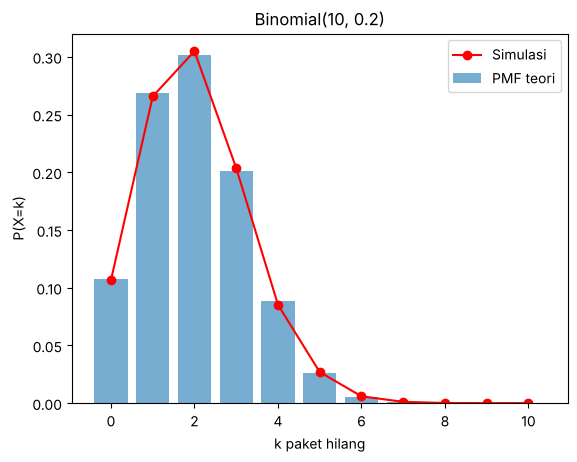

In [9]:
n,p = 10,0.2
pmf = lambda k: binom_pmf(k,n,p)
print("P(X=3)  =", round(pmf(3),4))
print("P(X<=3) =", round(sum(pmf(k) for k in range(4)),4))
print("P(X>=1) =", round(1-pmf(0),4))
E,V = moments(pmf, range(n+1))
print("E[X] =",round(E,4)," Var(X) =",round(V,4), " (rumus: np =",n*p,", npq =",n*p*(1-p),")")

# simulasi
random.seed(1)
sim = [sum(random.random()<p for _ in range(n)) for _ in range(50_000)]
cnt = Counter(sim)
print("Simulasi mean =", round(sum(sim)/len(sim),3))
ks = range(n+1)
plt.bar(ks,[pmf(k) for k in ks],alpha=.6,label="PMF teori")
plt.plot(ks,[cnt[k]/len(sim) for k in ks],'ro-',label="Simulasi")
plt.xlabel("k paket hilang"); plt.ylabel("P(X=k)"); plt.title("Binomial(10, 0.2)"); plt.legend(); plt.show()

**Interpretasi:** Rata-rata ada 2 paket hilang dari 10. Peluang minimal satu paket hilang ±89%, sehingga pada jaringan seperti ini retransmisi hampir selalu diperlukan. Titik simulasi menumpuk di atas batang teori → model Binomial cocok.

### Soal 3.2 — Geometrik: percobaan login
Peluang login berhasil tiap percobaan 0,3. Berapa P(sukses pertama tepat pada percobaan ke-4) dan percobaan yang diharapkan?
**Manual:** (0,7)³(0,3)=0,1029; E=1/p≈3,33; Var=(1−p)/p²≈7,78.

In [10]:
p=0.3
print("P(X=4)   =", round(geom_pmf(4,p),4))
print("P(X<=4)  =", round(1-(1-p)**4,4), "(rumus 1-(1-p)^4)")
E,V = moments(lambda k: geom_pmf(k,p), range(1,2000))
print("E[X] =",round(E,3),"(1/p =",round(1/p,3),")  Var =",round(V,3),"((1-p)/p^2 =",round((1-p)/p**2,3),")")

P(X=4)   = 0.1029
P(X<=4)  = 0.7599 (rumus 1-(1-p)^4)
E[X] = 3.333 (1/p = 3.333 )  Var = 7.778 ((1-p)/p^2 = 7.778 )


**Interpretasi:** Rata-rata dibutuhkan ±3,3 percobaan, tetapi variansnya besar (±7,8) sehingga banyak variasi antarpengguna. Penjumlahan sampai k=2000 cukup untuk mendekati deret tak hingga.

### Soal 3.3 — Hipergeometrik: sampling bug (tanpa pengembalian)
Sebuah sistem punya 50 modul, 8 di antaranya berbug. Tester memilih 10 modul acak. Berapa P(tepat 2 berbug) dan E[X]?
**Manual:** C(8,2)C(42,8)/C(50,10); E = N·n/M = 10·8/50 = 1,6.

In [11]:
M,n,N = 50,8,10
pmf = lambda k: hyper_pmf(k,M,n,N)
print("P(X=2) =", round(pmf(2),4))
print("P(X>=1) =", round(1-pmf(0),4))
E,V = moments(pmf, range(0,min(n,N)+1))
print("E =",round(E,3)," Var =",round(V,3))
print("Bandingkan Binomial (dengan pengembalian) P(X=2):", round(binom_pmf(2,N,n/M),4))

P(X=2) = 0.3217
P(X>=1) = 0.8568
E = 1.6  Var = 1.097
Bandingkan Binomial (dengan pengembalian) P(X=2): 0.2856


**Interpretasi:** Karena sampling tanpa pengembalian dari populasi kecil, hasil hipergeometrik (0,3217) berbeda jelas dari pendekatan binomial (0,2856), dan variansnya lebih kecil (1,097 vs 1,344). Selisih mengecil bila populasi jauh lebih besar dari sampel (faktor koreksi populasi terhingga).

### Soal 3.4 — Poisson: request per detik
Server menerima rata-rata λ=3 request/detik. Hitung P(X=5), P(X>5), dan bandingkan dengan Binomial(n=300, p=0,01) (pendekatan Poisson).

P(X=5)  = 0.1008
P(X>5)  = 0.0839
E = 3.0 Var = 3.0 (E = Var = lambda)


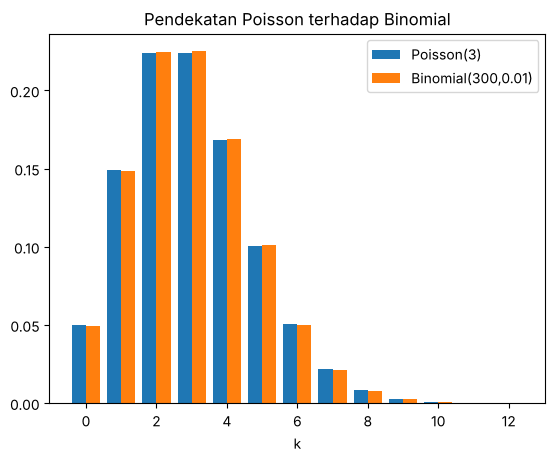

In [12]:
lam=3
print("P(X=5)  =", round(pois_pmf(5,lam),4))
print("P(X>5)  =", round(1-sum(pois_pmf(k,lam) for k in range(6)),4))
E,V = moments(lambda k: pois_pmf(k,lam), range(0,100))
print("E =",round(E,3),"Var =",round(V,3),"(E = Var = lambda)")
ks=range(0,13)
plt.bar([k-.2 for k in ks],[pois_pmf(k,3) for k in ks],width=.4,label="Poisson(3)")
plt.bar([k+.2 for k in ks],[binom_pmf(k,300,.01) for k in ks],width=.4,label="Binomial(300,0.01)")
plt.legend(); plt.xlabel("k"); plt.title("Pendekatan Poisson terhadap Binomial"); plt.show()

**Interpretasi:** Rata-rata = varians = 3 (ciri khas Poisson). Untuk n besar dan p kecil (np=3), Binomial dan Poisson hampir tidak terbedakan — alasan Poisson dipakai memodelkan kejadian jarang seperti request, error, atau serangan.

## 4. Pengembangan Contoh Permasalahan
### Soal 4.1 — Kebijakan password: minimal 1 huruf kecil, 1 kapital, 1 digit (inklusi–eksklusi)
Password 6 karakter dari 62 simbol (26 kecil, 26 kapital, 10 digit). Berapa banyak password **valid** dan berapa peluang password acak memenuhi kebijakan? Verifikasi rumus dengan *brute force* pada alfabet mini, lalu hitung nilai sebenarnya.

In [13]:
def valid_count(a,b,c,L):
    # a=#kecil, b=#kapital, c=#digit ; inklusi-eksklusi
    t=a+b+c
    return (t**L - (b+c)**L - (a+c)**L - (a+b)**L + c**L + b**L + a**L)

# verifikasi brute force alfabet mini
mini = {'a':'k','b':'k','A':'K','B':'K','1':'d','2':'d'}
L=4
bf = sum(1 for w in itertools.product(mini, repeat=L) if {mini[x] for x in w}=={'k','K','d'})
print("Brute force:", bf, " Rumus:", valid_count(2,2,2,L))

tot = 62**6
val = valid_count(26,26,10,6)
print("Valid:", f"{val:,}", "dari", f"{tot:,}", "-> peluang =", round(val/tot,4))

random.seed(7)
chars = [('k',26),('K',26),('d',10)]
alphabet = list(range(62))
def cls(i): return 0 if i<26 else 1 if i<52 else 2
N=100_000
ok=sum(len({cls(random.randrange(62)) for _ in range(6)})==3 for _ in range(N))/N
print("Simulasi    :", round(ok,4))

Brute force: 576  Rumus: 576
Valid: 33,294,892,800 dari 56,800,235,584 -> peluang = 0.5862


Simulasi    : 0.5871


**Interpretasi:** Rumus inklusi–eksklusi cocok dengan brute force (verifikasi konsep) dan simulasi. Hanya ±58,6% string acak 6 karakter yang lolos kebijakan, sehingga kebijakan ini mengurangi ruang pencarian sekitar 41% (hanya ±0,8 bit entropi) — **dampaknya kecil dibanding menambah panjang password**.

### Soal 4.2 — Coupon collector: mencoba semua server
Load balancer memilih 1 dari 6 server secara acak tiap request. Berapa request yang diharapkan sampai setiap server pernah dipilih?
**Manual:** E = n·Hₙ = 6(1+1/2+…+1/6)=**14,7**.

Teori   : 147/10 = 14.7
Simulasi: 14.699


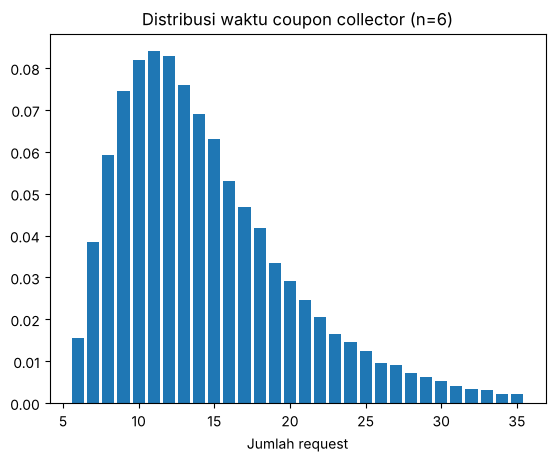

In [14]:
n=6
E_teori = n*sum(Fraction(1,k) for k in range(1,n+1))
def trial():
    seen=set(); t=0
    while len(seen)<n:
        seen.add(random.randrange(n)); t+=1
    return t
random.seed(3)
hasil=[trial() for _ in range(50_000)]
print("Teori   :", E_teori, "=", float(E_teori))
print("Simulasi:", round(sum(hasil)/len(hasil),3))
c=Counter(hasil); ks=sorted(c)[:30]
plt.bar(ks,[c[k]/len(hasil) for k in ks]); plt.xlabel("Jumlah request"); plt.title("Distribusi waktu coupon collector (n=6)"); plt.show()

**Interpretasi:** Dibutuhkan ±14,7 request (jauh lebih dari 6) karena server terakhir sulit "tertangkap". Distribusinya condong ke kanan: kadang butuh >30 request. Ini relevan untuk pengujian cakupan (*coverage*) dengan input acak.

## Kesimpulan
1. `math` + `itertools` + `Fraction` cukup untuk probabilitas klasik dengan **hasil eksak**.
2. Pencacahan ruang sampel memverifikasi rumus (5/36, 1/6, 14/17) tanpa mengandalkan hafalan.
3. Simulasi `random` mendekati teori; galat menurun sebanding 1/√N.
4. Keterbatasan: untuk distribusi kontinu, CDF, kuantil, dan visualisasi lanjut perlu `scipy`/`numpy` (lihat notebook 03–04).